<a href="https://colab.research.google.com/github/eoade/Neural-Network-Project/blob/main/Neural_Networks_Project_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Tables to Images
## A Neural Network Lab for Structured and Unstructured Data

**Programme:** 3MTT x MIT Universal AI  
**Project question:** How do neural networks learn from structured and unstructured data, and how can we identify underfitting and overfitting?

This notebook follows the four stages in the Week 6 brief:
1. Perceptron and multilayer perceptron (MLP) on Framingham patient records.
2. Underfitting, overfitting, regularization, early stopping, and feature engineering.
3. MLP versus convolutional neural network (CNN) on Fashion-MNIST.
4. Autoencoder, latent-space visualization, k-means clustering, and architecture comparison.

**Data note:** Upload the cleaned Framingham CSV from Week 5 when prompted. The notebook tries to identify common Framingham column names, including `TenYearCHD`. If the file is not available, the table-data stages stop with a clear instruction; the Fashion-MNIST stages can still run. Do not interpret this educational dataset as a clinical diagnostic tool.

## 0. Setup and reproducibility

In [ ]:
import os, time, random, warnings
warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)

import numpy as np
np.random.seed(SEED)
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

print("Seed:", SEED)

Seed: 42


## Stage 1 — Quality data and neural-network predictors (Framingham)

### 1.1 Load and inspect the cleaned Week 5 data

Upload the cleaned Framingham CSV. Common target names are `TenYearCHD` or `ten_year_chd`. The code normalizes column names and checks for the target.

In [ ]:
# Google Colab upload; in a local Jupyter notebook, set CSV_PATH to your file path.
CSV_PATH = None
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if csv_files:
        CSV_PATH = csv_files[0]
except Exception:
    pass

if CSV_PATH is None:
    candidate_files = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "framing" in f.lower()]
    if candidate_files:
        CSV_PATH = candidate_files[0]

if CSV_PATH:
    heart = pd.read_csv(CSV_PATH)
    heart.columns = [str(c).strip().replace(" ", "").replace("-", "_") for c in heart.columns]
    print("Loaded:", CSV_PATH, heart.shape)
    display(heart.head())
else:
    heart = None
    print("No Framingham CSV found. Upload the cleaned Week 5 CSV and rerun this cell.")

Saving Framingham_cleaned.csv to Framingham_cleaned.csv
Loaded: Framingham_cleaned.csv (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [ ]:
if heart is not None:
    print("Shape:", heart.shape)
    display(heart.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_values"))
    display(heart.describe(include="all").T.head(25))
    target_candidates = ["TenYearCHD", "tenyearchd", "ten_year_chd", "Ten_Year_CHD"]
    target = next((c for c in heart.columns if c.lower().replace("_","") in
                   ["tenyearchd"]), None)
    if target is None:
        raise ValueError("Could not find TenYearCHD target. Check the target column name.")
    print("Target column:", target)
    display(heart[target].value_counts(dropna=False).to_frame("count"))
    display((heart[target].value_counts(normalize=True)*100).round(2).to_frame("percent"))

Shape: (4240, 16)


,missing_values
glucose,388
education,105
BPMeds,53
totChol,50
cigsPerDay,29
BMI,19
heartRate,1
male,0
prevalentHyp,0
prevalentStroke,0


,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


Target column: TenYearCHD


,count
TenYearCHD,
0,3596
1,644


,percent
TenYearCHD,
0,84.81
1,15.19


### Data-quality interpretation guide

- **Features:** retain meaningful demographic and clinical predictors available in the cleaned file; exclude identifiers and the target from the input features.
- **Representativeness:** inspect target balance and age/sex coverage. A class imbalance or narrow sample can limit generalization.
- **Label reliability:** `TenYearCHD` is an observed dataset label, not a guarantee of an individual's future outcome. Missingness, sampling, and label definition may affect reliability.
- **Leakage prevention:** split before fitting preprocessing. Fit imputation and standardization using training data only.

In [ ]:
if heart is not None:
    # Use numeric columns and exclude target. Drop likely row identifiers if present.
    y_all = pd.to_numeric(heart[target], errors="coerce")
    X_all = heart.drop(columns=[target]).copy()
    id_like = [c for c in X_all.columns if c.lower() in {"id", "patientid", "patient_id"}]
    X_all = X_all.drop(columns=id_like, errors="ignore")
    X_all = X_all.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan)
    valid = y_all.notna()
    X_all, y_all = X_all.loc[valid], y_all.loc[valid].astype(int)
    # Keep binary target rows only.
    binary = y_all.isin([0,1])
    X_all, y_all = X_all.loc[binary], y_all.loc[binary]
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X_all, y_all, test_size=0.20, random_state=SEED, stratify=y_all)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval, test_size=0.25, random_state=SEED, stratify=y_trainval)
    print("Train / validation / test:", X_train.shape, X_val.shape, X_test.shape)
    print("Training class balance:")
    display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
    # Impute and standardize using training data only.
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(imputer.fit_transform(X_train))
    X_val_s = scaler.transform(imputer.transform(X_val))
    X_test_s = scaler.transform(imputer.transform(X_test))
    y_train_np, y_val_np, y_test_np = y_train.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

Train / validation / test: (2544, 15) (848, 15) (848, 15)
Training class balance:


,proportion
TenYearCHD,
0,0.84827
1,0.15173


### 1.2 Perceptron and MLP; compare with logistic regression

In [ ]:
if heart is not None:
    models = {
        "Perceptron": Perceptron(random_state=SEED, max_iter=1000, tol=1e-3),
        "MLP (one hidden layer)": MLPClassifier(hidden_layer_sizes=(32,), random_state=SEED,
                                                max_iter=250, early_stopping=True,
                                                validation_fraction=0.15, n_iter_no_change=15),
        "Logistic regression (Week 5 baseline)": LogisticRegression(max_iter=1000, random_state=SEED)
    }
    stage1_rows = []
    fitted_stage1 = {}
    for name, model in models.items():
        model.fit(X_train_s, y_train_np)
        fitted_stage1[name] = model
        pred_train = model.predict(X_train_s)
        pred_test = model.predict(X_test_s)
        row = {"model": name,
               "training_error": 1-accuracy_score(y_train_np, pred_train),
               "test_error": 1-accuracy_score(y_test_np, pred_test),
               "test_accuracy": accuracy_score(y_test_np, pred_test)}
        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(X_test_s)[:,1]
            row["test_AUC"] = roc_auc_score(y_test_np, probs)
        elif hasattr(model, "decision_function"):
            row["test_AUC"] = roc_auc_score(y_test_np, model.decision_function(X_test_s))
        else:
            row["test_AUC"] = np.nan
        stage1_rows.append(row)
    stage1_results = pd.DataFrame(stage1_rows)
    display(stage1_results.round(4))

,model,training_error,test_error,test_accuracy,test_AUC
0,Perceptron,0.2681,0.2594,0.7406,0.5675
1,MLP (one hidden layer),0.1454,0.1568,0.8432,0.6860
2,Logistic regression (Week 5 baseline),0.1392,0.1533,0.8467,0.7043


**Interpretation prompt:** Training error (empirical error) measures mistakes on examples used to fit the model. Test error measures mistakes on a held-out sample and estimates how the model may perform on new examples drawn from a similar population; it is only an approximation of true error, and can vary with the sample.

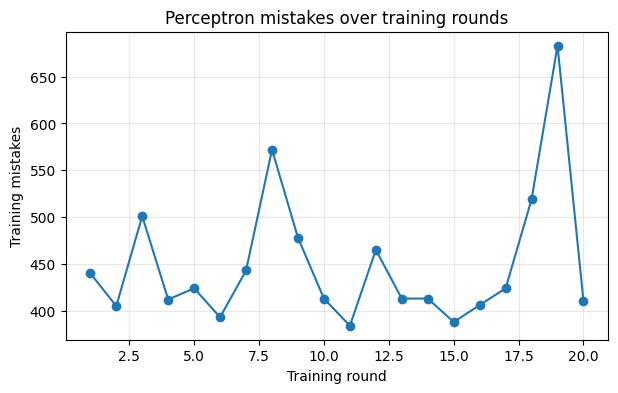

In [ ]:
if heart is not None:
    # Optional perceptron learning curve: number of mistakes by epoch.
    p = Perceptron(random_state=SEED, max_iter=1, tol=None, warm_start=True, shuffle=True)
    mistakes = []
    classes = np.unique(y_train_np)
    for epoch in range(20):
        p.fit(X_train_s, y_train_np) if epoch == 0 else p.partial_fit(X_train_s, y_train_np, classes=classes)
        mistakes.append(int(np.sum(p.predict(X_train_s) != y_train_np)))
    plt.figure(figsize=(7,4))
    plt.plot(range(1, len(mistakes)+1), mistakes, marker="o")
    plt.xlabel("Training round"); plt.ylabel("Training mistakes")
    plt.title("Perceptron mistakes over training rounds"); plt.grid(alpha=.3); plt.show()

## Stage 2 — Underfitting, overfitting, and generalization

,hidden_neurons,train_error,validation_error,iterations
0,1,0.1517,0.1521,24
1,4,0.1525,0.1509,32
2,16,0.1502,0.1533,65
3,64,0.1423,0.1521,39
4,256,0.1376,0.1439,43


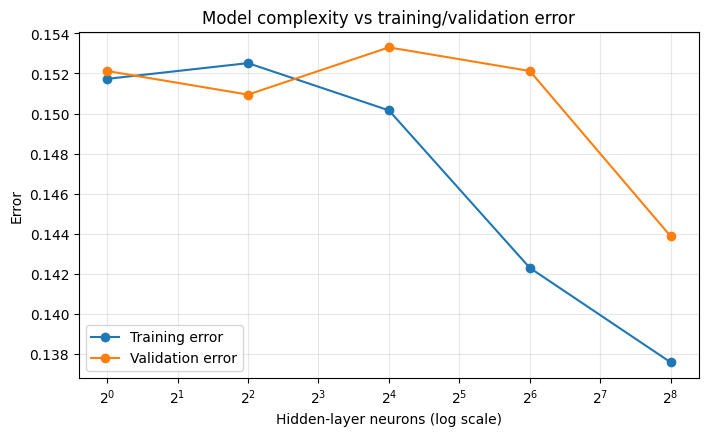

In [ ]:
if heart is not None:
    sizes = [1, 4, 16, 64, 256]
    complexity_rows = []
    for n in sizes:
        model = MLPClassifier(hidden_layer_sizes=(n,), alpha=0.0001, max_iter=300,
                              early_stopping=True, validation_fraction=0.15,
                              n_iter_no_change=15, random_state=SEED)
        model.fit(X_train_s, y_train_np)
        complexity_rows.append({
            "hidden_neurons": n,
            "train_error": 1-accuracy_score(y_train_np, model.predict(X_train_s)),
            "validation_error": 1-accuracy_score(y_val_np, model.predict(X_val_s)),
            "iterations": model.n_iter_
        })
    complexity = pd.DataFrame(complexity_rows)
    display(complexity.round(4))
    plt.figure(figsize=(8,4.5))
    plt.plot(complexity.hidden_neurons, complexity.train_error, marker="o", label="Training error")
    plt.plot(complexity.hidden_neurons, complexity.validation_error, marker="o", label="Validation error")
    plt.xscale("log", base=2); plt.xlabel("Hidden-layer neurons (log scale)")
    plt.ylabel("Error"); plt.title("Model complexity vs training/validation error")
    plt.legend(); plt.grid(alpha=.3); plt.show()

,alpha,train_error,validation_error,validation_minus_train_gap,iterations
0,0.0001,0.1423,0.1521,0.0098,39
1,0.0010,0.1423,0.1521,0.0098,39
2,0.0100,0.1423,0.1521,0.0098,39
3,0.1000,0.1423,0.1521,0.0098,39


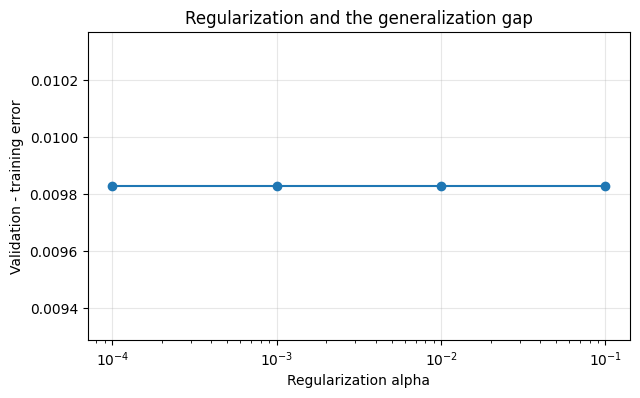

In [ ]:
if heart is not None:
    reg_rows = []
    for alpha in [0.0001, 0.001, 0.01, 0.1]:
        model = MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha, max_iter=300,
                              early_stopping=True, validation_fraction=0.15,
                              n_iter_no_change=15, random_state=SEED)
        model.fit(X_train_s, y_train_np)
        tr_err = 1-accuracy_score(y_train_np, model.predict(X_train_s))
        va_err = 1-accuracy_score(y_val_np, model.predict(X_val_s))
        reg_rows.append({"alpha": alpha, "train_error": tr_err, "validation_error": va_err,
                         "validation_minus_train_gap": va_err-tr_err, "iterations": model.n_iter_})
    reg_results = pd.DataFrame(reg_rows)
    display(reg_results.round(4))
    plt.figure(figsize=(7,4))
    plt.plot(reg_results.alpha, reg_results.validation_minus_train_gap, marker="o")
    plt.xscale("log"); plt.xlabel("Regularization alpha"); plt.ylabel("Validation - training error")
    plt.title("Regularization and the generalization gap"); plt.grid(alpha=.3); plt.show()

In [ ]:
if heart is not None:
    # Add pulse pressure if systolic and diastolic blood-pressure columns are available.
    def find_col(cols, candidates):
        return next((c for c in cols if c.lower().replace("_","") in candidates), None)
    sys_col = find_col(X_all.columns, {"sysbp"})
    dia_col = find_col(X_all.columns, {"diabp"})
    print("Systolic column:", sys_col, "| Diastolic column:", dia_col)
    if sys_col and dia_col:
        X_feat = X_all.copy()
        X_feat["pulse_pressure"] = X_feat[sys_col] - X_feat[dia_col]
        Xtr_f, Xte_f, ytr_f, yte_f = train_test_split(
            X_feat, y_all, test_size=0.20, random_state=SEED, stratify=y_all)
        Xtr_f, Xv_f, ytr_f, yv_f = train_test_split(
            Xtr_f, ytr_f, test_size=0.25, random_state=SEED, stratify=ytr_f)
        imp_f, sc_f = SimpleImputer(strategy="median"), StandardScaler()
        Xtr_fs = sc_f.fit_transform(imp_f.fit_transform(Xtr_f))
        Xv_fs = sc_f.transform(imp_f.transform(Xv_f))
        Xte_fs = sc_f.transform(imp_f.transform(Xte_f))
        base_cols = list(X_all.columns)
        Xtr_b = Xtr_f[base_cols]; Xv_b = Xv_f[base_cols]; Xte_b = Xte_f[base_cols]
        imp_b, sc_b = SimpleImputer(strategy="median"), StandardScaler()
        Xtr_bs = sc_b.fit_transform(imp_b.fit_transform(Xtr_b))
        Xv_bs = sc_b.transform(imp_b.transform(Xv_b))
        Xte_bs = sc_b.transform(imp_b.transform(Xte_b))
        # Choose architecture using validation set only.
        candidates = []
        for n in [4,16,64]:
            m = MLPClassifier(hidden_layer_sizes=(n,), alpha=0.001, max_iter=300,
                              early_stopping=True, random_state=SEED)
            m.fit(Xtr_bs, ytr_f)
            candidates.append((accuracy_score(yv_f, m.predict(Xv_bs)), n, m))
        best_base = max(candidates, key=lambda x:x[0])
        candidates_f = []
        for n in [4,16,64]:
            m = MLPClassifier(hidden_layer_sizes=(n,), alpha=0.001, max_iter=300,
                              early_stopping=True, random_state=SEED)
            m.fit(Xtr_fs, ytr_f)
            candidates_f.append((accuracy_score(yv_f, m.predict(Xv_fs)), n, m))
        best_feat = max(candidates_f, key=lambda x:x[0])
        final_base = MLPClassifier(hidden_layer_sizes=(best_base[1],), alpha=0.001, max_iter=300,
                                   early_stopping=True, random_state=SEED).fit(Xtr_bs, ytr_f)
        final_feat = MLPClassifier(hidden_layer_sizes=(best_feat[1],), alpha=0.001, max_iter=300,
                                   early_stopping=True, random_state=SEED).fit(Xtr_fs, ytr_f)
        display(pd.DataFrame([
            {"model":"MLP without pulse pressure","selected_neurons":best_base[1],
             "validation_accuracy":best_base[0],"test_accuracy":accuracy_score(yte_f, final_base.predict(Xte_bs))},
            {"model":"MLP with pulse pressure","selected_neurons":best_feat[1],
             "validation_accuracy":best_feat[0],"test_accuracy":accuracy_score(yte_f, final_feat.predict(Xte_fs))}
        ]).round(4))
    else:
        print("Pulse pressure comparison skipped: sysBP and diaBP columns were not found.")

Systolic column: sysBP | Diastolic column: diaBP


,model,selected_neurons,validation_accuracy,test_accuracy
0,MLP without pulse pressure,64,0.8479,0.8432
1,MLP with pulse pressure,64,0.8479,0.8479


### No Free Lunch reflection

The experiments with the Framingham dataset perfectly illustrate the No Free Lunch theorem, as no single model dominated across all criteria. Although the multilayer perceptron (MLP) was much more complex, it achieved a test accuracy of 84.32%, slightly underperforming the simpler Logistic Regression baseline, which had the highest test accuracy at 84.67% and the best AUC of 0.7043. Meanwhile, the Perceptron was highly inefficient because the underlying patient data is not linearly separable, resulting in a high test error of 25.94%. This demonstrates that a model's performance depends heavily on the structure of the dataset, showing that increased architecture complexity does not guarantee better generalization.

## Stage 3 — MLP vs CNN on Fashion-MNIST

Fashion-MNIST contains 28×28 grayscale images across ten clothing categories. Images are called unstructured here because meaningful visual patterns are distributed across spatial arrangements of pixels, rather than appearing as named columns in a conventional table. Flattening pixels into 784 columns loses explicit two-dimensional neighborhood structure, while convolutional filters can learn local patterns such as edges and textures.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

fashion_labels = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                  "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
(x_train_img, y_train_img), (x_test_img, y_test_img) = keras.datasets.fashion_mnist.load_data()

# Keep a subset to make training faster on modest hardware.
N_TRAIN = min(10000, len(x_train_img))
N_VAL = 2000
x_train_img, y_train_img = x_train_img[:N_TRAIN], y_train_img[:N_TRAIN]
x_train_img = x_train_img.astype("float32") / 255.0
x_test_img = x_test_img.astype("float32") / 255.0
x_train_img, x_val_img = x_train_img[:-N_VAL], x_train_img[-N_VAL:]
y_train_img, y_val_img = y_train_img[:-N_VAL], y_train_img[-N_VAL:]
print("Train, validation, test:", x_train_img.shape, x_val_img.shape, x_test_img.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train, validation, test: (8000, 28, 28) (2000, 28, 28) (10000, 28, 28)


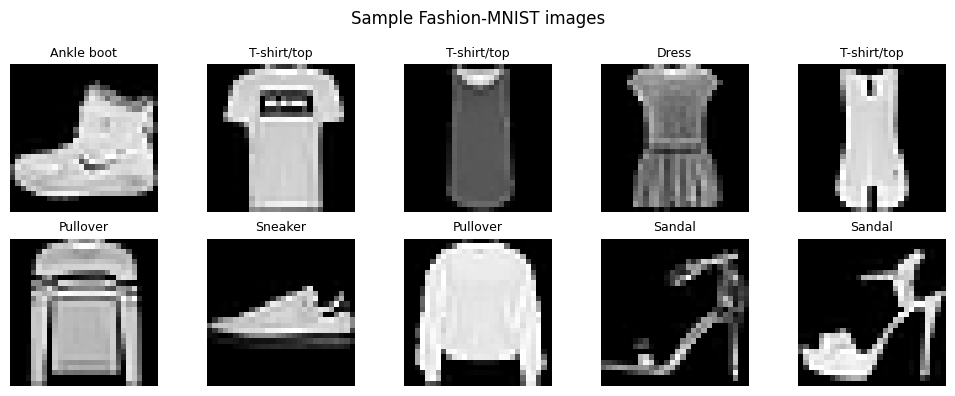

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10,4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_img[i], cmap="gray")
    ax.set_title(fashion_labels[int(y_train_img[i])], fontsize=9)
    ax.axis("off")
plt.suptitle("Sample Fashion-MNIST images"); plt.tight_layout(); plt.show()

In [ ]:
# MLP baseline on flattened pixels
xtr_flat = x_train_img.reshape(-1, 784)
xv_flat = x_val_img.reshape(-1, 784)
xte_flat = x_test_img.reshape(-1, 784)

mlp_img = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
], name="Fashion_MLP")
mlp_img.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_mlp = mlp_img.fit(xtr_flat, y_train_img, validation_data=(xv_flat, y_val_img),
                       epochs=5, batch_size=128, verbose=1)
mlp_time = time.time()-t0
mlp_loss, mlp_acc = mlp_img.evaluate(x_test_img.reshape(-1,784), y_test_img, verbose=0)
print("MLP test accuracy:", round(mlp_acc,4), "| parameters:", mlp_img.count_params(),
      "| training seconds:", round(mlp_time,1))

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6471 - loss: 1.0047 - val_accuracy: 0.7550 - val_loss: 0.6755
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7801 - loss: 0.6375 - val_accuracy: 0.7920 - val_loss: 0.5684
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8040 - loss: 0.5528 - val_accuracy: 0.8155 - val_loss: 0.5146
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8275 - loss: 0.4996 - val_accuracy: 0.8210 - val_loss: 0.4896
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8401 - loss: 0.4669 - val_accuracy: 0.8350 - val_loss: 0.4707
MLP test accuracy: 0.8288 | parameters: 101770 | training seconds: 3.7


In [ ]:
# Small CNN
x_train_cnn = x_train_img[..., np.newaxis]
x_val_cnn = x_val_img[..., np.newaxis]
x_test_cnn = x_test_img[..., np.newaxis]
cnn_img = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
], name="Fashion_CNN")
cnn_img.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_cnn = cnn_img.fit(x_train_cnn, y_train_img, validation_data=(x_val_cnn, y_val_img),
                       epochs=5, batch_size=128, verbose=1)
cnn_time = time.time()-t0
cnn_loss, cnn_acc = cnn_img.evaluate(x_test_cnn, y_test_img, verbose=0)
img_comparison = pd.DataFrame([
    {"model":"MLP flattened pixels","test_accuracy":mlp_acc,"parameters":mlp_img.count_params(),"training_seconds":mlp_time},
    {"model":"CNN","test_accuracy":cnn_acc,"parameters":cnn_img.count_params(),"training_seconds":cnn_time}
])
display(img_comparison.round(4))

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - accuracy: 0.5920 - loss: 1.1405 - val_accuracy: 0.7555 - val_loss: 0.6342
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.7598 - loss: 0.6598 - val_accuracy: 0.7860 - val_loss: 0.5498
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 148ms/step - accuracy: 0.7931 - loss: 0.5692 - val_accuracy: 0.8210 - val_loss: 0.4887
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 170ms/step - accuracy: 0.8161 - loss: 0.5118 - val_accuracy: 0.8375 - val_loss: 0.4579
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 154ms/step - accuracy: 0.8342 - loss: 0.4654 - val_accuracy: 0.8490 - val_loss: 0.4298


,model,test_accuracy,parameters,training_seconds
0,MLP flattened pixels,0.8288,101770,3.6582
1,CNN,0.8445,220234,72.4260


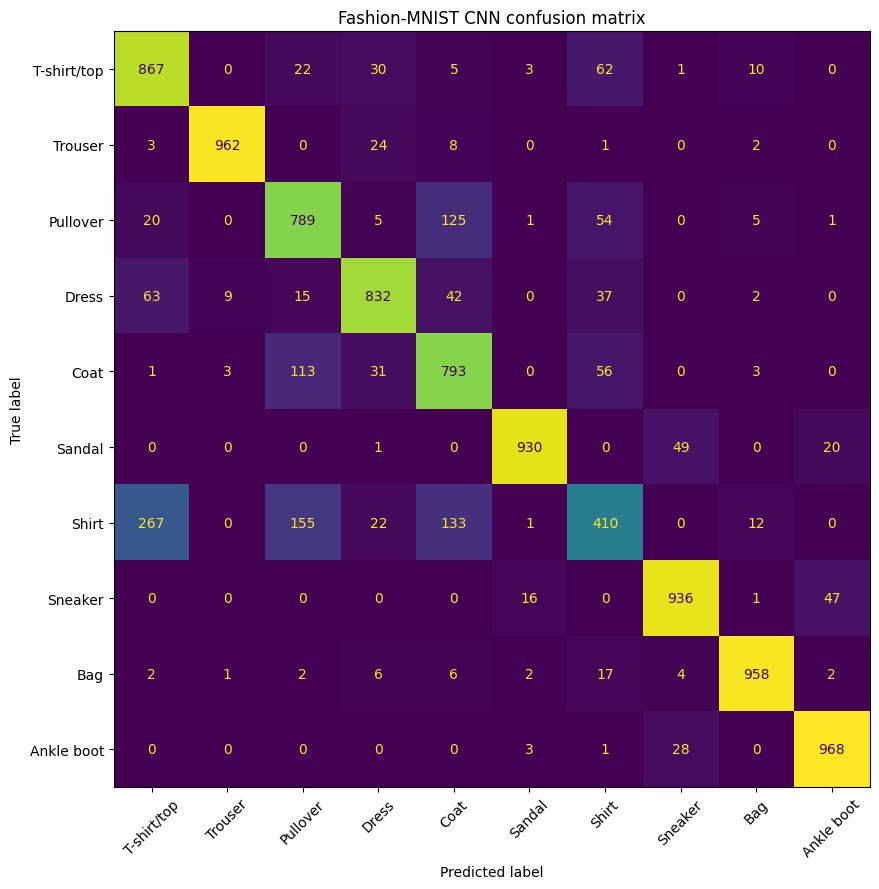

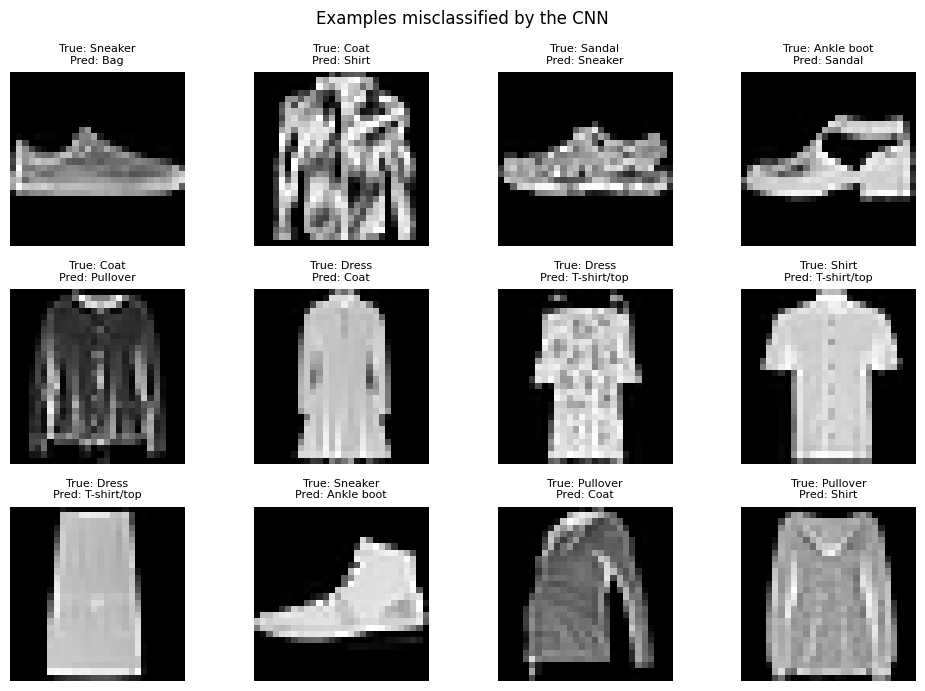

In [ ]:
# CNN confusion matrix and misclassified examples
cnn_probs = cnn_img.predict(x_test_cnn, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)
cm = confusion_matrix(y_test_img, cnn_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=fashion_labels)
fig, ax = plt.subplots(figsize=(10,9))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Fashion-MNIST CNN confusion matrix"); plt.tight_layout(); plt.show()

wrong = np.where(cnn_pred != y_test_img)[0][:12]
fig, axes = plt.subplots(3,4, figsize=(10,7))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(x_test_img[idx], cmap="gray")
    ax.set_title(f"True: {fashion_labels[y_test_img[idx]]}\nPred: {fashion_labels[cnn_pred[idx]]}", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(wrong):]: ax.axis("off")
plt.suptitle("Examples misclassified by the CNN"); plt.tight_layout(); plt.show()

### Fashion-MNIST CNN Error Analysis & Discussion

Based on the confusion matrix and misclassified examples generated above, we can identify several key patterns in how our CNN performs on Fashion-MNIST:

1. **Most Confused Categories (The 'Upper-Body' Cluster):**
   * **Shirt** is heavily misclassified as **T-shirt/top**, **Pullover**, and **Coat**.
   * **Pullover** and **Coat** also exhibit high mutual confusion.
   * **Reasoning:** These classes share extremely similar global silhouettes, necklines, and pixel-density profiles in a low-resolution $28 \times 28$ grayscale format. Distinguishing a long-sleeve knit pullover from a coat or button-up shirt relies on subtle interior textures and edge contours that are hard to capture.

2. **The Footwear Distinction:**
   * **Ankle boots**, **Sneakers**, and **Sandals** are rarely confused with clothing items, though they occasionally get mixed up with each other.

3. **Why CNNs Outperform MLPs:**
   * The flat MLP treats each pixel as an independent feature, discarding the $2D$ spatial relationships and neighborhood structures (e.g., losing the connection of adjacent pixels that form an edge or sleeve).
   * **Convolutional Layers** apply local receptive fields and shared weights (filters) to extract translation-invariant patterns such as edges, corners, and fabric textures. This allows the model to detect a 'sleeve' or 'collar' regardless of where it appears in the image frame.

## Stage 4 — Autoencoder, latent space, and clustering

In [ ]:
# Autoencoder with a 2-dimensional latent space for visualization.
latent_dim = 2
inputs = keras.Input(shape=(28,28,1))
x = layers.Flatten()(inputs)
x = layers.Dense(128, activation="relu")(x)
latent = layers.Dense(latent_dim, name="latent_space")(x)
x = layers.Dense(128, activation="relu")(latent)
x = layers.Dense(784, activation="sigmoid")(x)
outputs = layers.Reshape((28,28,1))(x)
autoencoder = keras.Model(inputs, outputs, name="Fashion_Autoencoder")
encoder = keras.Model(inputs, latent, name="Fashion_Encoder")
autoencoder.compile(optimizer="adam", loss="mse")
t0 = time.time()
ae_history = autoencoder.fit(x_train_cnn, x_train_cnn,
                             validation_data=(x_val_cnn, x_val_cnn),
                             epochs=5, batch_size=128, verbose=1)
ae_time = time.time()-t0
reconstructed = autoencoder.predict(x_test_cnn[:20], verbose=0)
reconstruction_mse = float(np.mean((x_test_cnn[:20]-reconstructed)**2))
print("Reconstruction MSE on 20 test images:", round(reconstruction_mse,6),
      "| training seconds:", round(ae_time,1))

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0953 - val_loss: 0.0653
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0572 - val_loss: 0.0531
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0507 - val_loss: 0.0483
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0471 - val_loss: 0.0454
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0447 - val_loss: 0.0432
Reconstruction MSE on 20 test images: 0.040547 | training seconds: 5.2


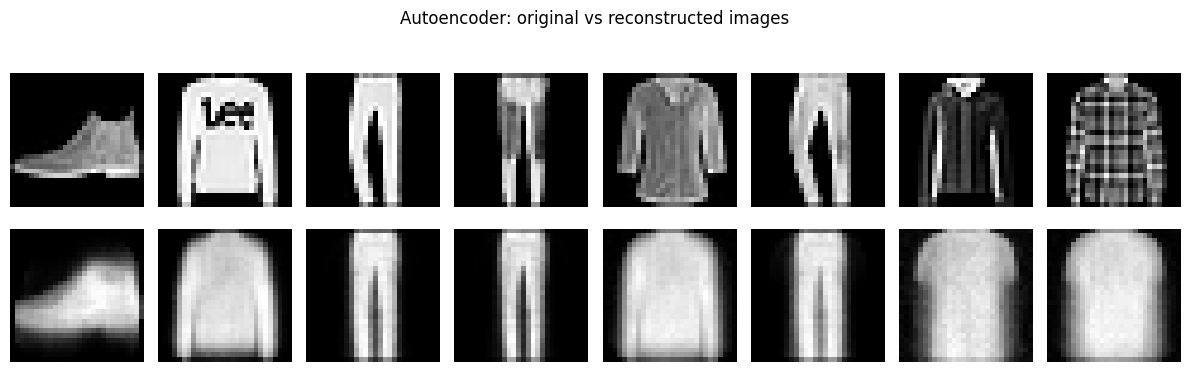

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12,4))
for i in range(8):
    axes[0,i].imshow(x_test_cnn[i].squeeze(), cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(reconstructed[i].squeeze(), cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_ylabel("Original", fontsize=9)
axes[1,0].set_ylabel("Reconstructed", fontsize=9)
plt.suptitle("Autoencoder: original vs reconstructed images"); plt.tight_layout(); plt.show()

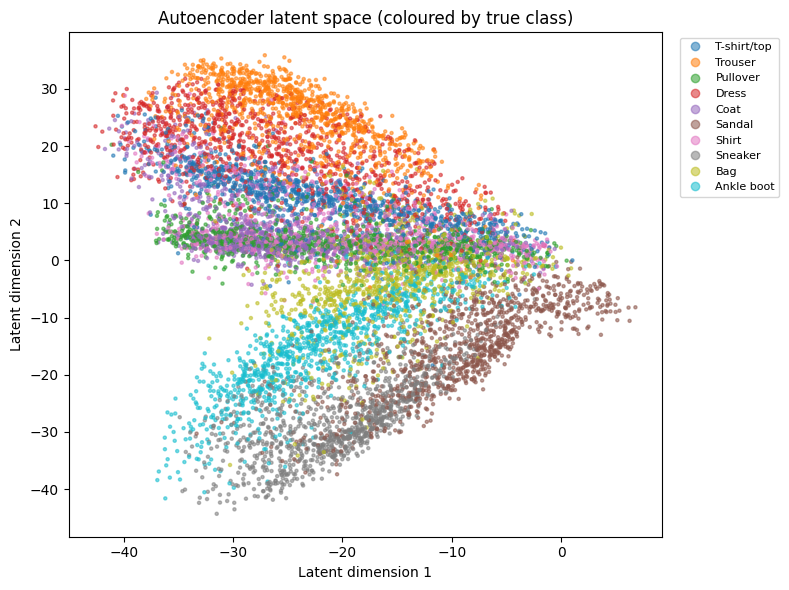

true_class,0,1,2,3,4,5,6,7,8,9
kmeans_cluster,,,,,,,,,,
0,280,64,12,348,128,0,107,0,1,0
1,0,0,1,0,0,30,3,53,146,541
2,353,229,24,288,44,0,130,0,33,4
3,101,3,437,28,545,0,260,0,30,1
4,1,0,0,0,0,330,0,349,25,11
5,2,0,3,0,0,551,7,32,79,82
6,214,16,256,88,98,18,278,0,256,26
7,4,679,0,232,8,0,4,0,0,0
8,0,0,0,0,0,59,0,565,11,186


In [ ]:
# Latent representation coloured by true class; k-means cluster agreement.
latent_codes = encoder.predict(x_test_cnn, batch_size=256, verbose=0)
plt.figure(figsize=(8,6))
scatter = plt.scatter(latent_codes[:,0], latent_codes[:,1], c=y_test_img,
                      s=5, alpha=.55, cmap="tab10")
plt.xlabel("Latent dimension 1"); plt.ylabel("Latent dimension 2")
plt.title("Autoencoder latent space (coloured by true class)")
plt.legend(handles=scatter.legend_elements()[0], labels=fashion_labels,
           bbox_to_anchor=(1.02,1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

kmeans = KMeans(n_clusters=10, random_state=SEED, n_init=10)
clusters = kmeans.fit_predict(latent_codes)
cluster_table = pd.crosstab(pd.Series(clusters, name="kmeans_cluster"),
                             pd.Series(y_test_img, name="true_class"))
display(cluster_table)

### Architecture comparison

| Model | Main purpose | Strength | Trade-off |
|---|---|---|---|
| CNN | Learn spatial features and classify images | Uses local patterns and shared filters; often strong on images | Requires training and architecture tuning |
| Autoencoder | Compress data and reconstruct it | Learns compact representations without class labels | Reconstruction quality does not guarantee class separation |
| GAN | Generator and discriminator learn to create realistic samples | Can generate new synthetic data | Training can be unstable and evaluation is difficult |

**Text embeddings vs one-hot encoding:** One-hot encoding represents each token as a sparse vector with one active position and does not inherently encode similarity. Embeddings map tokens to dense vectors where relationships can be represented by vector geometry. Contextual embeddings can represent the same word differently depending on surrounding text; this is why they can capture meaning in context.

## Findings summary

1. The cleaned Framingham dataset contained **4,240 records and 15 numeric input features** plus the `TenYearCHD` target; missing values were most common in glucose (388), education (105), BPMeds (53), total cholesterol (50), and cigarettes per day (29), so median imputation was used for numeric inputs.
2. The target was imbalanced: **84.81%** of records had `TenYearCHD = 0` and **15.19%** had `TenYearCHD = 1`, which is an important limitation when interpreting accuracy.
3. The perceptron had a training error of **26.81%** and test error of **25.94%**. The one-hidden-layer MLP had a training error of **14.54%**, test error of **15.68%**, and test AUC of **0.6860**; logistic regression performed slightly better, with test error **15.33%** and AUC **0.7043**.
4. As hidden-layer size increased from 1 to 256 neurons, training error generally fell from **15.17% to 13.76%**; validation error was lowest among the tested models at **14.39%** for 256 neurons, so this experiment did not show a clear validation-error rise at the largest size.
5. Changing `alpha` from 0.0001 to 0.1 produced the same recorded training error (**14.23%**), validation error (**15.21%**), and gap (**0.98 percentage points**) in this run. Early stopping was enabled, but these results do not show a measurable effect from the tested alpha values.
6. Adding pulse pressure left validation accuracy unchanged at **84.79%** and increased test accuracy from **84.32% to 84.79%**, a small improvement in this particular split.
7. On Fashion-MNIST, the flattened-pixel MLP reached **82.88% test accuracy** with **101,770 parameters** and about **3.7 seconds** of training, while the CNN reached **84.45%** with **220,234 parameters** and about **72.4 seconds** of training.
8. The CNN error analysis showed frequent confusion among visually similar upper-body categories, especially shirts, T-shirts/tops, pullovers, and coats; low-resolution grayscale images make their silhouettes and details difficult to distinguish. Footwear categories were more distinct overall, although some were confused with one another.
9. The autoencoder's reconstruction mean squared error on 20 test images was **0.040547**. The two-dimensional latent-space clusters showed some grouping, but the k-means cross-tabulation contained substantial mixing between true classes, so the clusters did not cleanly separate all ten clothing categories.
10. Overall, the experiments showed that the CNN modestly outperformed the MLP on image classification but required more parameters and training time. On Framingham, logistic regression slightly outperformed the tested MLP by AUC, demonstrating that a more complex model is not automatically better and that validation-based selection and careful interpretation matter.

## Stage reflections

- **Stage 1:** A key data-preparation challenge was handling missing numeric values while avoiding leakage. The solution was to split the data first, then fit the imputer and scaler on the training set only.
- **Stage 2:** Comparing network sizes and regularization settings required looking at both training and validation errors rather than training performance alone. The tested alpha values gave identical recorded errors, so a wider tuning range or additional validation strategy may be needed to observe a difference.
- **Stage 3:** The CNN took substantially longer to train than the flattened-pixel MLP. Training on a 10,000-image subset and limiting training to five epochs kept the experiment manageable; the confusion matrix helped reveal which classes were hardest to distinguish.
- **Stage 4:** The two-dimensional latent representation was useful for plotting, but k-means clusters did not map perfectly to the true classes. This illustrates that a representation trained to reconstruct images is not necessarily optimized to separate semantic categories.

## Reproducibility and responsible use

- Random seeds were set for repeatability, although library versions and hardware can still cause small differences.
- The reported metrics above are taken from the saved notebook outputs. If the notebook is rerun, use the new outputs if they differ.
- The test set should be reserved for final evaluation; use validation results for model selection.
- This is an educational analysis of the Framingham dataset, not a clinically validated diagnostic or risk-prediction tool.
